In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
print(tf.__version__)

2.21.0


In [2]:
tf.keras.utils.set_random_seed(42)
EPOCHS = 5
BATCH_SIZE = 128
TRAIN_SIZE = 20000
TEST_SIZE = 5000

In [3]:
(x_train_all, y_train_all), (x_test_all, y_test_all) = tf.keras.datasets.cifar10.load_data()
classes = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 144s 1us/step


In [4]:
rng = np.random.default_rng(42)
a = rng.permutation(len(x_train_all))[:TRAIN_SIZE]
b = rng.permutation(len(x_test_all))[:TEST_SIZE]
x_train = x_train_all[a].astype("float32") / 255
y_train = y_train_all[a].ravel()
x_test = x_test_all[b].astype("float32") / 255
y_test = y_test_all[b].ravel()
print(x_train.shape, x_test.shape)

(20000, 32, 32, 3) (5000, 32, 32, 3)


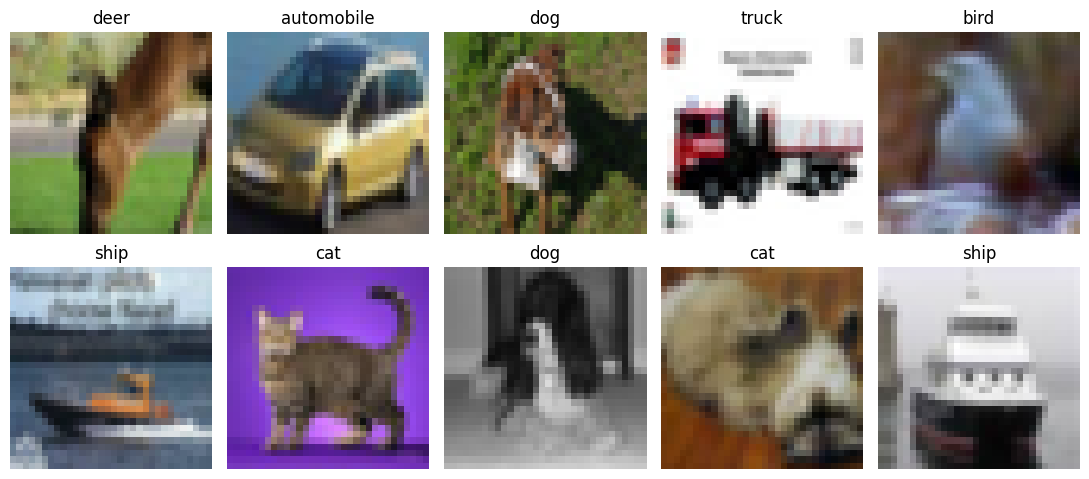

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i]); ax.set_title(classes[y_train[i]]); ax.axis("off")
plt.tight_layout(); plt.show()

In [6]:
def conv_block(x, filters, stride=1):
    x = layers.Conv2D(filters, 3, strides=stride, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x)

In [7]:
def build_simple_cnn():
    inp = layers.Input((32, 32, 3))
    x = conv_block(inp, 32)
    x = layers.MaxPooling2D()(x)
    x = conv_block(x, 64)
    x = layers.MaxPooling2D()(x)
    x = conv_block(x, 128)
    x = layers.GlobalAveragePooling2D()(x)
    out = layers.Dense(10, activation="softmax")(x)
    return Model(inp, out, name="Simple_CNN")
simple = build_simple_cnn()
simple.summary()

Model: "Simple_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,210 (371.91 KB)

 Trainable params: 94,762 (370.16 KB)

 Non-trainable params: 448 (1.75 KB)

In [8]:
def residual_block(x, filters, stride=1):
    shortcut = x
    y = conv_block(x, filters, stride)
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    if stride != 1 or x.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding="same", use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    return layers.ReLU()(layers.Add()([y, shortcut]))

In [9]:
def build_resnet():
    inp = layers.Input((32, 32, 3))
    x = conv_block(inp, 32)
    x = residual_block(x, 32)
    x = residual_block(x, 64, 2)
    x = residual_block(x, 64)
    x = residual_block(x, 128, 2)
    x = layers.GlobalAveragePooling2D()(x)
    out = layers.Dense(10, activation="softmax")(x)
    return Model(inp, out, name="ResNet_Style")
resnet = build_resnet()
resnet.summary()

Model: "ResNet_Style"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │      9,216 │ re_lu_3[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_4 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │      9,216 │ re_lu_4[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ re_lu_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_5 (ReLU)      │ (None, 32, 32,    │          0 │ add[0][0]         │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │     18,432 │ re_lu_5[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_6 (ReLU)      │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │     36,864 │ re_lu_6[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │      2,048 │ re_lu_5[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_7[0][0]  

 Total params: 384,234 (1.47 MB)

 Trainable params: 382,634 (1.46 MB)

 Non-trainable params: 1,600 (6.25 KB)

In [10]:
def compile_model(model):
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
compile_model(simple)
compile_model(resnet)

In [11]:
start = time.perf_counter()
h_simple = simple.fit(x_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_split=0.2)
t_simple = time.perf_counter() - start

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.4201 - loss: 1.6200 - val_accuracy: 0.0920 - val_loss: 3.3274
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.5322 - loss: 1.3283 - val_accuracy: 0.1210 - val_loss: 3.7941
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5756 - loss: 1.2098 - val_accuracy: 0.1813 - val_loss: 3.4772
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6039 - loss: 1.1336 - val_accuracy: 0.2473 - val_loss: 3.0002
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6256 - loss: 1.0741 - val_accuracy: 0.3192 - val_loss: 2.6032


In [12]:
start = time.perf_counter()
h_resnet = resnet.fit(x_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_split=0.2)
t_resnet = time.perf_counter() - start

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - accuracy: 0.4206 - loss: 1.5685 - val_accuracy: 0.0938 - val_loss: 3.4663
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.5525 - loss: 1.2360 - val_accuracy: 0.1500 - val_loss: 2.9928
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.6263 - loss: 1.0464 - val_accuracy: 0.2968 - val_loss: 2.1775
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.6781 - loss: 0.9114 - val_accuracy: 0.4633 - val_loss: 1.5919
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.7186 - loss: 0.7997 - val_accuracy: 0.3893 - val_loss: 2.1360


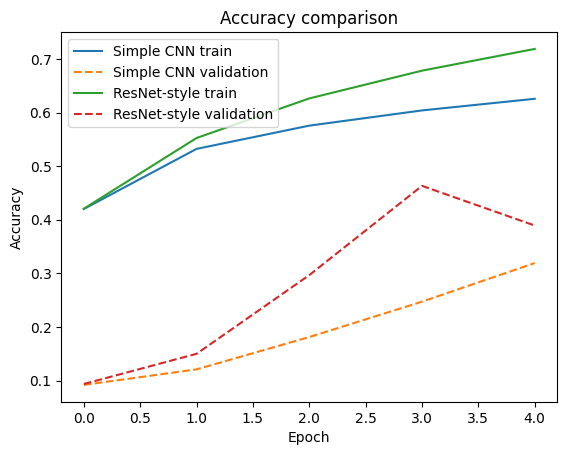

In [13]:
for name, hist in [("Simple CNN", h_simple), ("ResNet-style", h_resnet)]:
    plt.plot(hist.history["accuracy"], label=name + " train")
    plt.plot(hist.history["val_accuracy"], "--", label=name + " validation")
plt.title("Accuracy comparison"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.show()

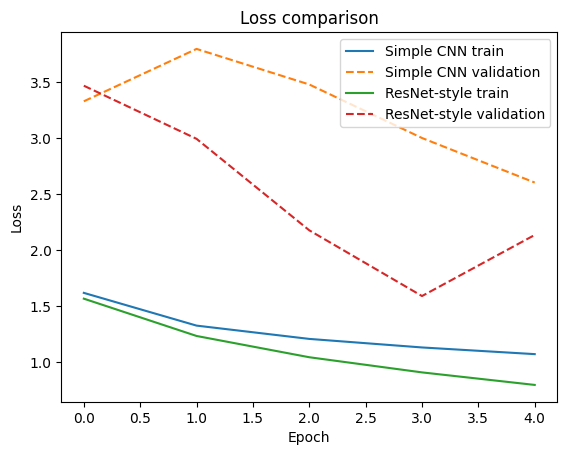

In [14]:
for name, hist in [("Simple CNN", h_simple), ("ResNet-style", h_resnet)]:
    plt.plot(hist.history["loss"], label=name + " train")
    plt.plot(hist.history["val_loss"], "--", label=name + " validation")
plt.title("Loss comparison"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()

In [15]:
loss_simple, acc_simple = simple.evaluate(x_test, y_test, verbose=0)
loss_resnet, acc_resnet = resnet.evaluate(x_test, y_test, verbose=0)
print("Simple CNN:", acc_simple, "ResNet-style:", acc_resnet)

Simple CNN: 0.3070000112056732 ResNet-style: 0.3831999897956848


In [16]:
pred_simple = np.argmax(simple.predict(x_test, verbose=0), axis=1)
pred_resnet = np.argmax(resnet.predict(x_test, verbose=0), axis=1)

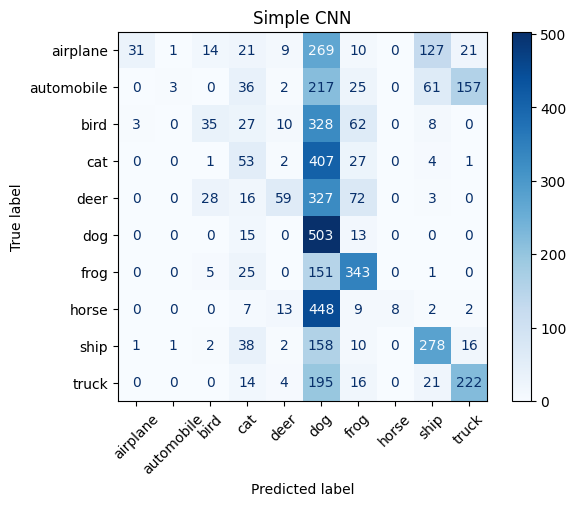

In [17]:
ConfusionMatrixDisplay.from_predictions(y_test, pred_simple, display_labels=classes, xticks_rotation=45, cmap="Blues")
plt.title("Simple CNN"); plt.show()

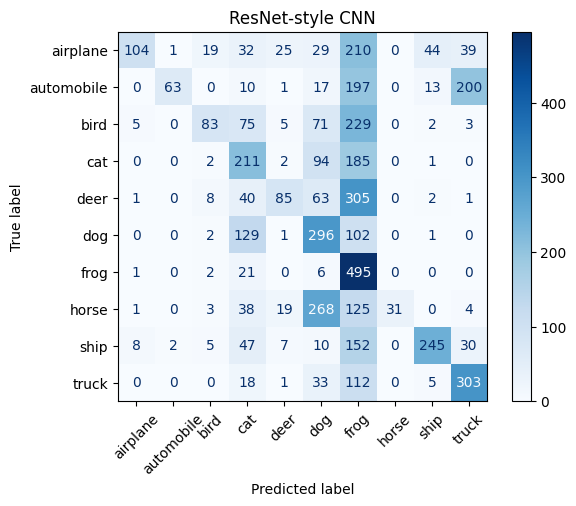

In [18]:
ConfusionMatrixDisplay.from_predictions(y_test, pred_resnet, display_labels=classes, xticks_rotation=45, cmap="Blues")
plt.title("ResNet-style CNN"); plt.show()

In [19]:
print("SIMPLE CNN")
print(classification_report(y_test, pred_simple, target_names=classes, zero_division=0))
print("RESNET-STYLE CNN")
print(classification_report(y_test, pred_resnet, target_names=classes, zero_division=0))

SIMPLE CNN
              precision    recall  f1-score   support

    airplane       0.89      0.06      0.12       503
  automobile       0.60      0.01      0.01       501
        bird       0.41      0.07      0.13       473
         cat       0.21      0.11      0.14       495
        deer       0.58      0.12      0.19       505
         dog       0.17      0.95      0.28       531
        frog       0.58      0.65      0.62       525
       horse       1.00      0.02      0.03       489
        ship       0.55      0.55      0.55       506
       truck       0.53      0.47      0.50       472

    accuracy                           0.31      5000
   macro avg       0.55      0.30      0.26      5000
weighted avg       0.55      0.31      0.26      5000

RESNET-STYLE CNN
              precision    recall  f1-score   support

    airplane       0.87      0.21      0.33       503
  automobile       0.95      0.13      0.22       501
        bird       0.67      0.18      0.28       

In [20]:
results = pd.DataFrame({"Model": ["Simple CNN", "ResNet-style CNN"], "Accuracy": [acc_simple, acc_resnet], "Test Loss": [loss_simple, loss_resnet], "Parameters": [simple.count_params(), resnet.count_params()], "Training Time (seconds)": [t_simple, t_resnet]})
display(results)

,Model,Accuracy,Test Loss,Parameters,Training Time (seconds)
0,Simple CNN,0.3070,2.645418,95210,16.504159
1,ResNet-style CNN,0.3832,2.182258,384234,32.620574


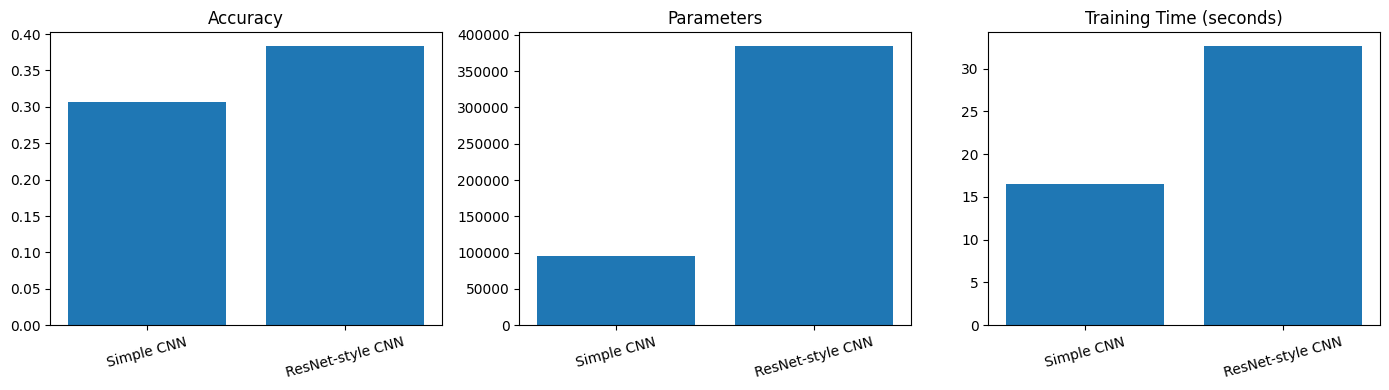

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, column in zip(axes, ["Accuracy", "Parameters", "Training Time (seconds)"]):
    ax.bar(results["Model"], results[column]); ax.set_title(column); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

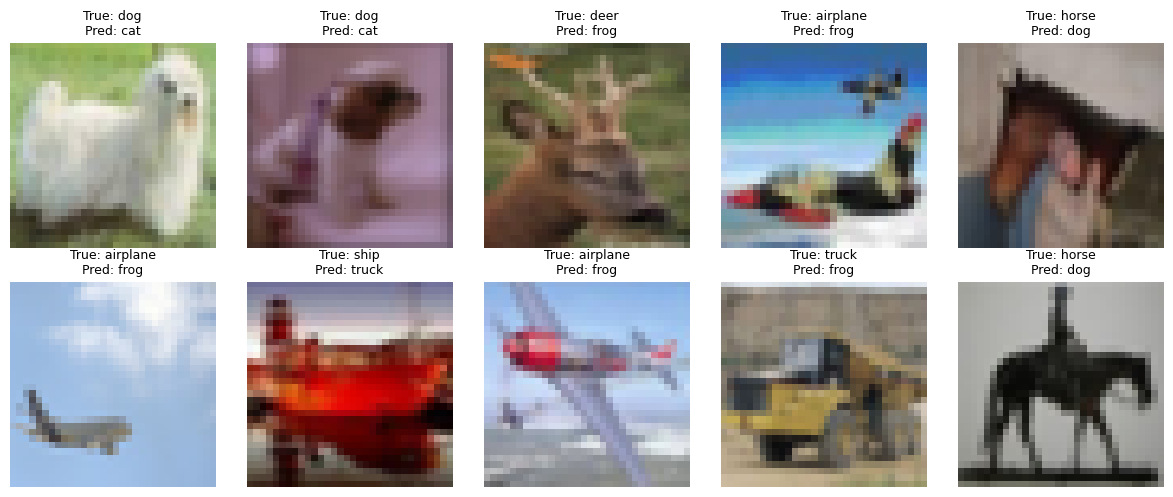

In [22]:
errors = np.flatnonzero(pred_resnet != y_test)[:10]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax in axes.flat: ax.axis("off")
for ax, i in zip(axes.flat, errors):
    ax.imshow(x_test[i]); ax.set_title(f"True: {classes[y_test[i]]}\nPred: {classes[pred_resnet[i]]}", fontsize=9)
plt.tight_layout(); plt.show()

In [23]:
print("Higher test accuracy:", results.loc[results["Accuracy"].idxmax(), "Model"])
print("Results depend on training epochs, sample size, and random initialization.")

Higher test accuracy: ResNet-style CNN
Results depend on training epochs, sample size, and random initialization.
